# Checks of the fit with the systematic uncertainties

Three checks that the ABCD fit of `03_limits.ipynb` behaves with the systematics in, for one
signal point per final state, on the cards with corrections and systematics and the integrated
estimate (`systematics_study.LIMITS_METHOD`), the likelihood of the AN's limits:

5. **Signal injection.** Toy datasets generated with the signal at a known strength, the
   point's expected limit and three times it, and fitted back
   (`sidm/scripts/run_combine_toys.py`). The pull of $r$ (its fitted minus its injected
   value, over its uncertainty) follows a unit Gaussian if the fit is unbiased and its
   uncertainty right, and every nuisance that the data do not constrain comes back as
   $0 \pm 1$.
6. **Likelihood scans.** $-2\Delta\ln L$ against $r$, with every nuisance and with
   statistics only, on the Asimov dataset without signal and with the signal at the
   expected limit, and against each systematic, with $r$ floating
   (`sidm/scripts/run_combine_scan.py`).
7. **Correlations.** The correlation matrix of every parameter of the signal-plus-background
   fit to the Asimov dataset with the signal at the expected limit
   (`sidm/scripts/run_combine_pulls.py`), the free background parameters included.

**Rerun after `03_limits.ipynb`** whenever an entry is added to `systematics.yaml`. Like
`04_systematic_effects.ipynb`, it reads the outputs of 03_limits from EOS and stops if they
are not from the current `systematics.yaml`.

**Blinded.** The cards take regions B, C and D from data, and region A's observation is the
prediction, never data. The toys are generated from the pre-fit model, whose control regions
sit at the data counts, and the cards' data_obs is never fitted. The figures and fit outputs go to EOS, under `fit_checks/` in the output directory of
03_limits.

**Interpretations.** Each section ends with an interpretation of its results and of what they
mean for the analysis, written for the run named in it. Revise them when a rerun changes the
picture, for example after adding a systematic.

In [1]:
import json, os, shutil, sys, tempfile, warnings
from pathlib import Path
import fsspec
import numpy as np
from IPython.display import Image, display

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy
import plot_tools as pt   # sidm/studies/limit_plotting, put on the path by systematics_study

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)
dt = sysstudy.dt

CAMPAIGN = "systematics_v3"
dt.use_campaign(CAMPAIGN)
INPUT_DIR = sysstudy.eos_url(dt.CAMPAIGN.bkg_dir)   # the merged outputs of the campaign
LIMITS_DIR = f"{INPUT_DIR}{sysstudy.LIMITS_SUFFIX}"   # the data-driven outputs of 03_limits.ipynb
OUTPUT_DIR = f"{LIMITS_DIR}/fit_checks"
REGISTRY = sysstudy.load_registry()
KAPPAS = sysstudy.limits_outputs(LIMITS_DIR, REGISTRY)["kappas"]   # stops if 03_limits needs a rerun
LIMIT = set(sysstudy.limit_grid(study.signal_points())) & set(KAPPAS)
EXPECTED = {r["signal"]: r["exp"] for r in pt.as_rows(f"{LIMITS_DIR}/limits_with_{sysstudy.LIMITS_METHOD}/limits.csv")}
POINTS = {"SR_2mu2e": "2Mu2E_500GeV_1p2GeV_1p9mm", "SR_4mu": "4Mu_500GeV_1p2GeV_1p9mm"}
NTOYS = 500   # per point and injected strength
COMBINE = sysstudy.find_combine()
WORK = Path(tempfile.mkdtemp(prefix=f"fit_checks_{CAMPAIGN}_"))   # removed at the end
FIGURES = WORK / "figures"


def show(path):
    """Display a figure that plot_tools saved"""
    display(Image(filename=str(path.with_suffix(".png"))))


print("inputs: ", INPUT_DIR, "and", LIMITS_DIR)
print("outputs:", OUTPUT_DIR)
print("Combine:", "on the PATH" if COMBINE and COMBINE.no_cmsenv else COMBINE.combine_cmssw if COMBINE else "not found")
print("systematics:", ", ".join(REGISTRY), f"| {len(LIMIT)} points on the limit grid")
print("points:", ", ".join(f"{p} (expected limit {EXPECTED[p]:.3g} fb)" for p in POINTS.values()))

inputs:  root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v3 and root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v3_limits_data
outputs: root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v3_limits_data/fit_checks
Combine: /uscms_data/d3/scampbel/CMSSW_14_1_0_pre4
systematics: lumi_13TeV, CMS_pileup, CMS_l1_prefiring, CMS_jet_energy, CMS_eff_m_id, CMS_eff_e_reco, CMS_eff_g_pixelveto | 96 points on the limit grid
points: 2Mu2E_500GeV_1p2GeV_1p9mm (expected limit 4.8 fb), 4Mu_500GeV_1p2GeV_1p9mm (expected limit 5.04 fb)


## 5. Signal injection

Left, the fitted $r$ of the toys against the injected value, with their mean; middle, its
pull against a unit Gaussian, with the median and the half-width of the central 68% of the
pulls (the mean and width of a Gaussian, but not thrown off by a few toys with a broken
uncertainty); right, the mean and spread of every fitted
nuisance over the toys against $0 \pm 1$. The limits keep $r \geq 0$, so a toy whose best fit
would lie below zero stops there: at the expected limit, which is about two standard
deviations above zero, some toys gather at $r = 0$ and in the left tail of the pull. At three
times the expected limit that should no longer happen. Fits that fail (status not 0) are
left out and counted in the title.

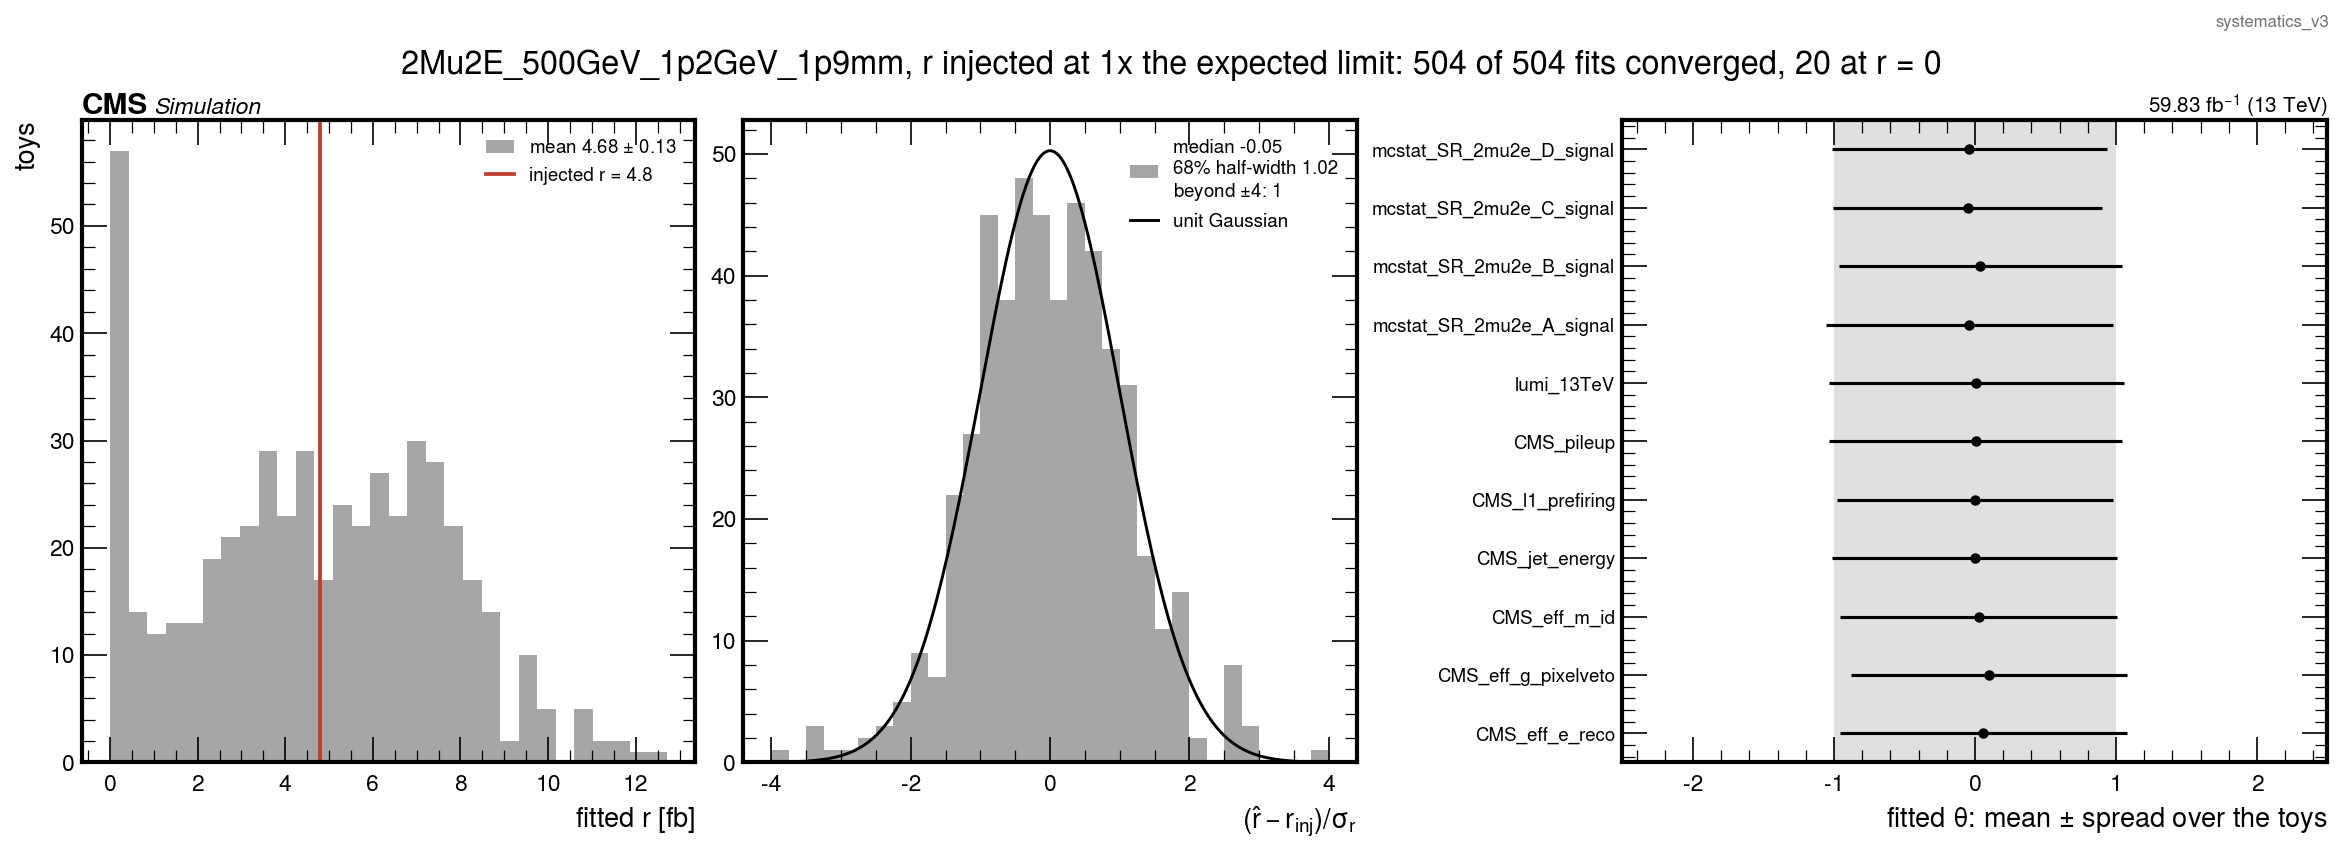

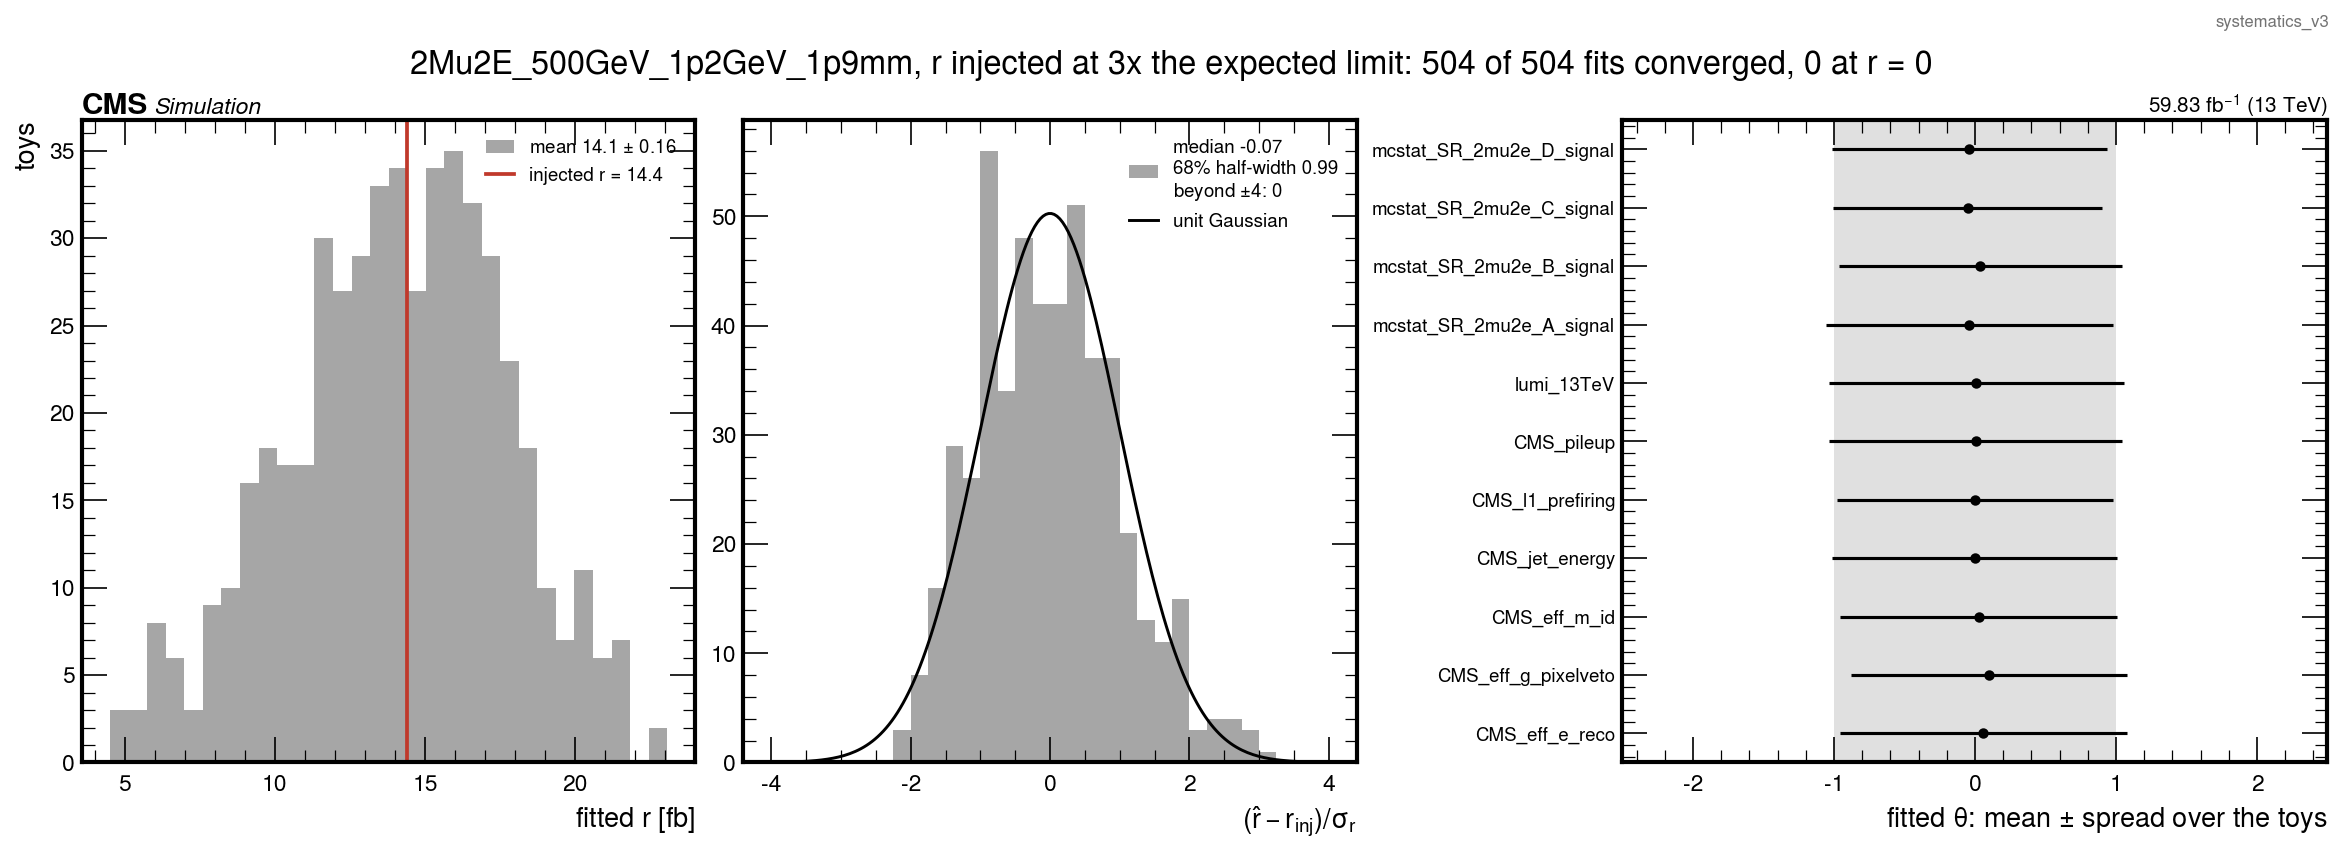

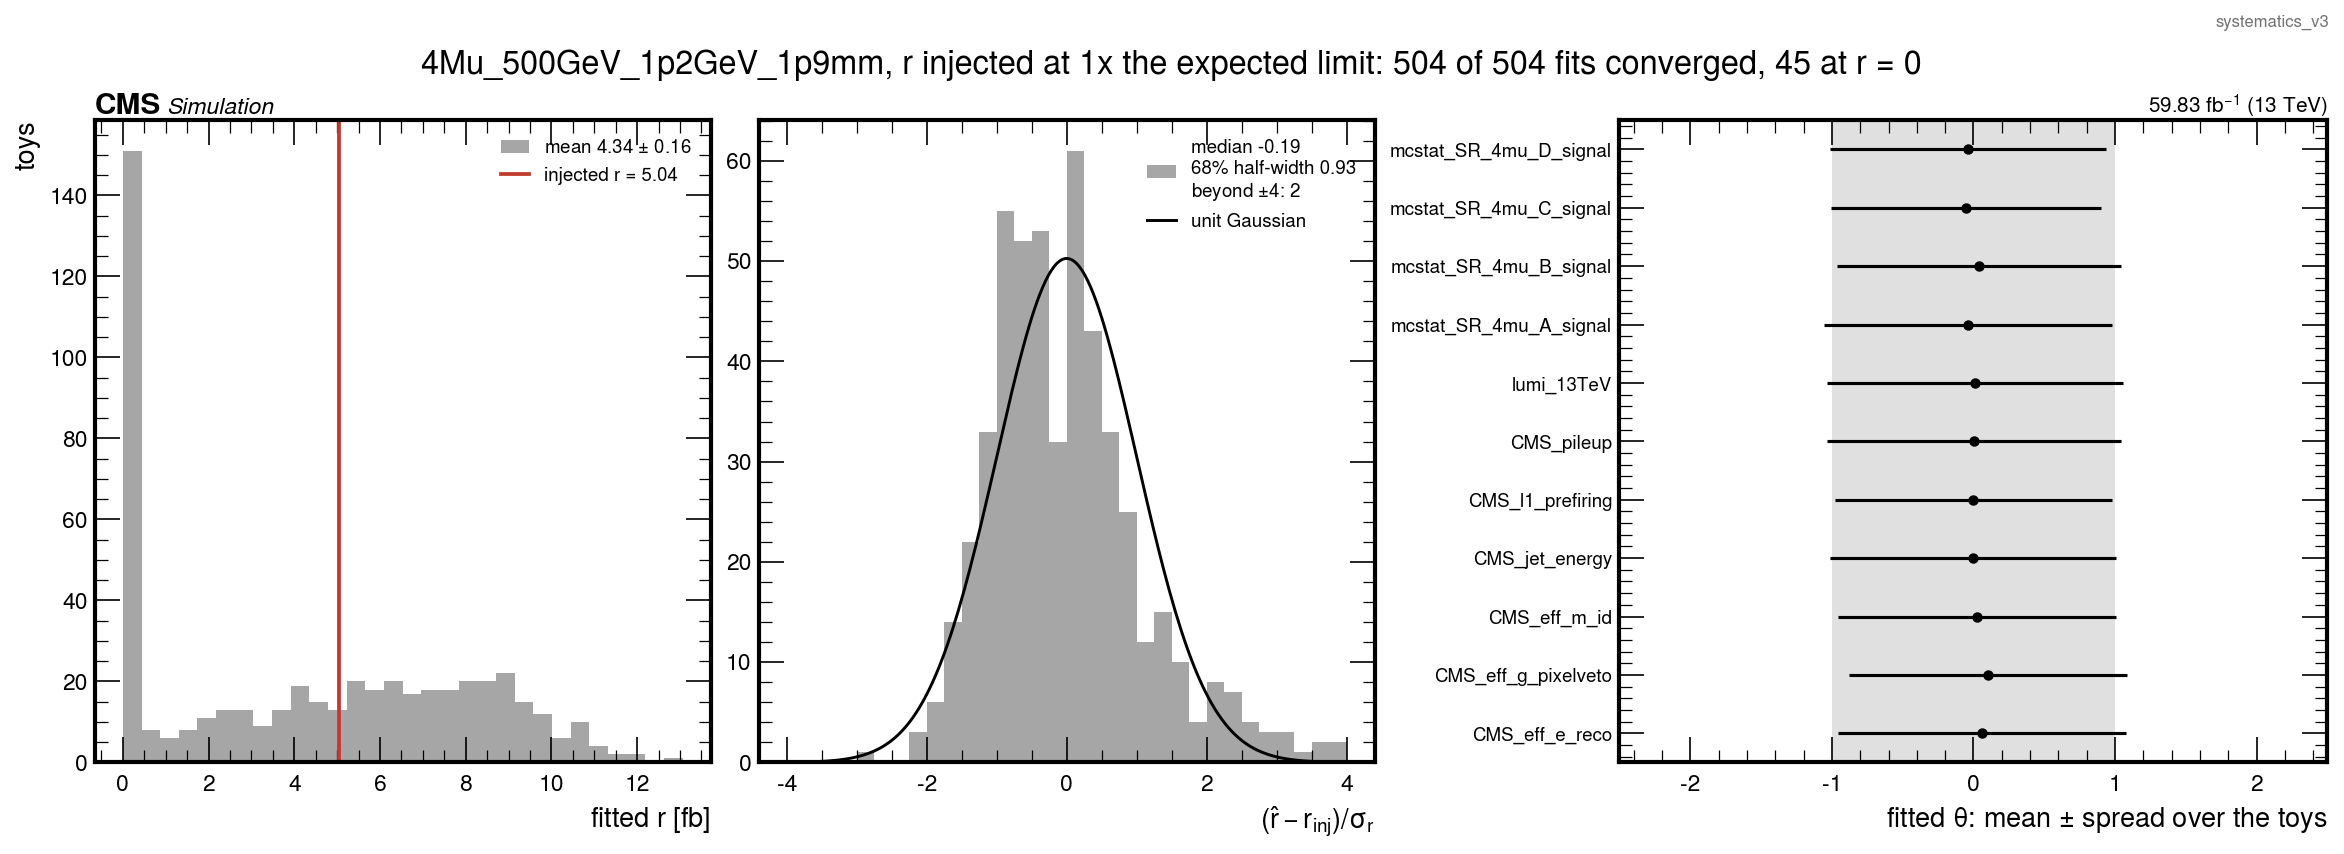

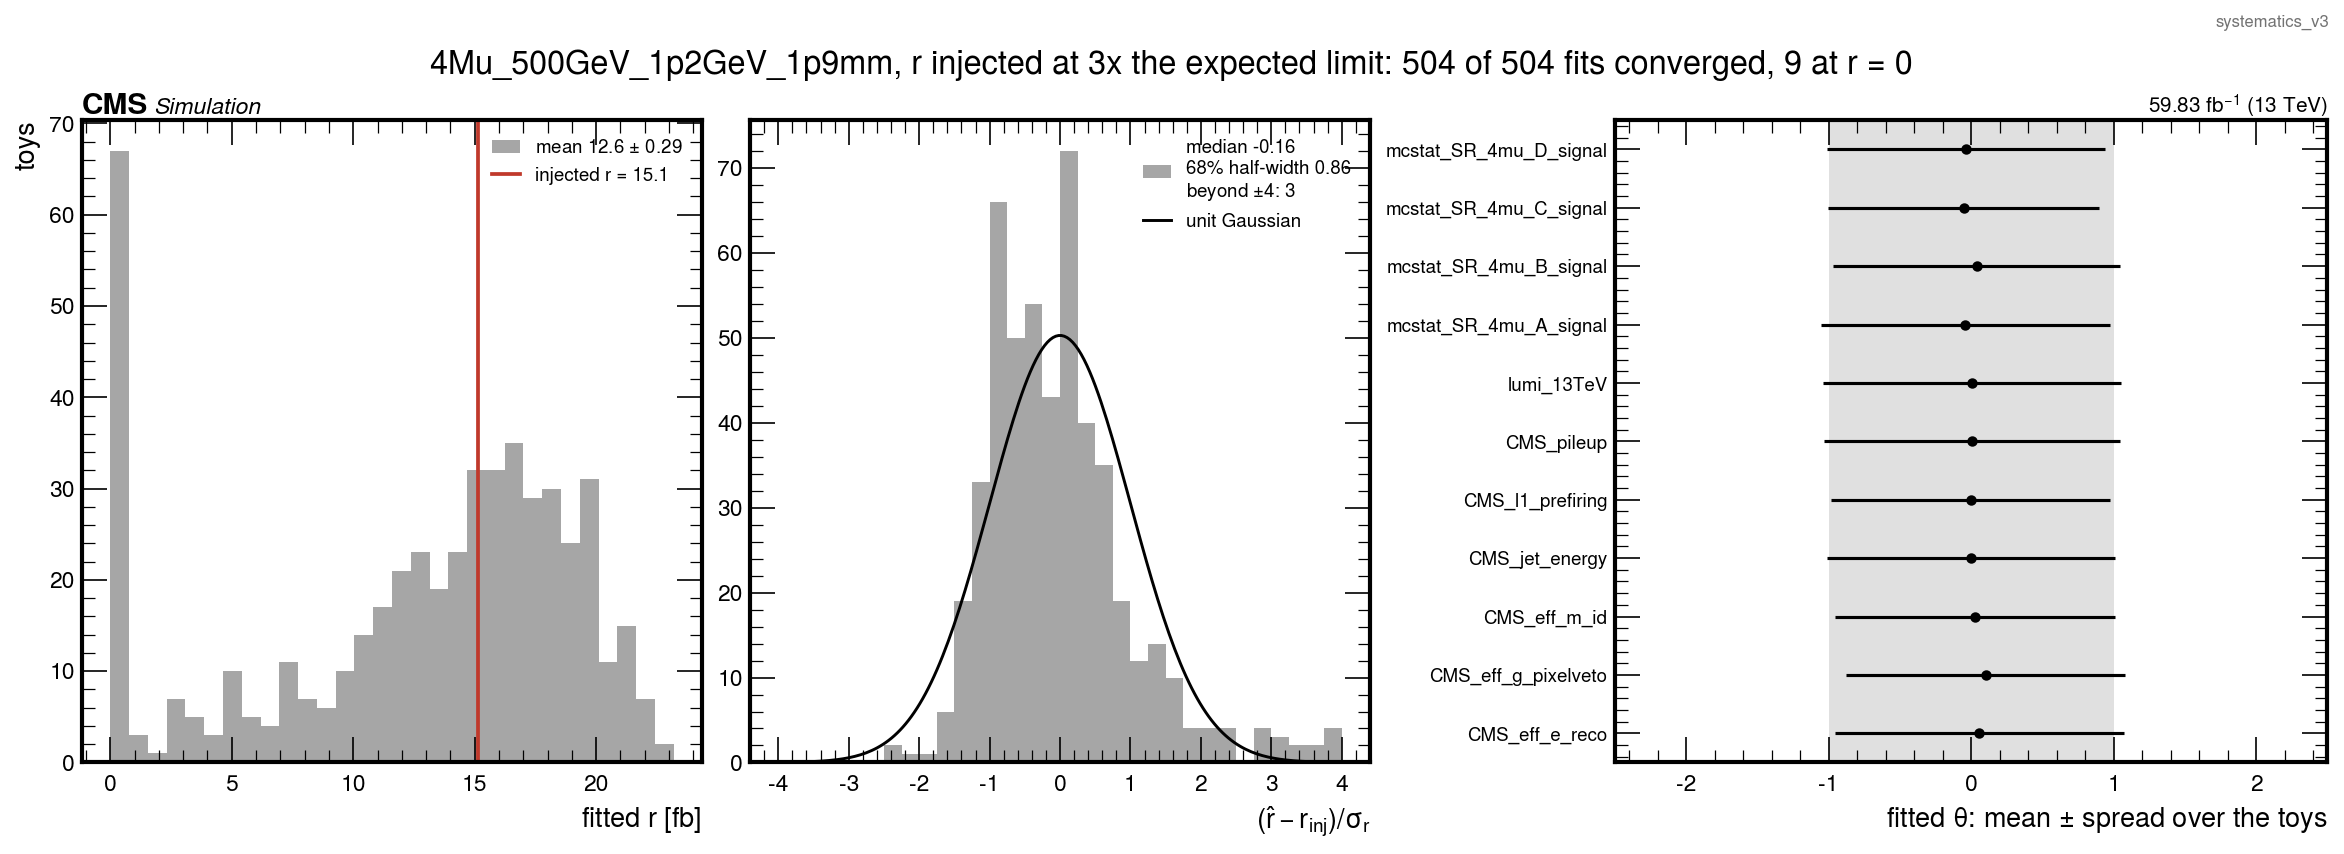

In [2]:
if COMBINE is None:
    raise RuntimeError("Combine is not available here: put `combine` on the PATH or set COMBINE_CMSSW_BASE.")
CARDS = WORK / "cards"
sysstudy.download(f"{LIMITS_DIR}/cards_with_{sysstudy.LIMITS_METHOD}", CARDS)   # the cards with corrections and systematics

for channel, point in POINTS.items():
    card = CARDS / f"datacard_shape_{channel}_{point}.txt"
    for factor in (1, 3):
        outdir = WORK / f"toys_{point}_x{factor}"
        sysstudy.run_script("run_combine_toys.py", card, "--outdir", outdir,
                            "--expect-signal", f"{factor * EXPECTED[point]:.6g}", "--toys", NTOYS, "-j", "8",
                            combine=COMBINE, log=WORK / f"toys_{point}_x{factor}.log")
        toys = json.loads((outdir / "toys.json").read_text())
        show(pt.bias_plot(toys, FIGURES, CAMPAIGN, f"injection_{point}_x{factor}",
                          title=f"{point}, r injected at {factor}x the expected limit"))

**Interpretation (run of 2026-11-24: signal from `systematics_v3`, background from regions B, C
and D of `systematics_data_v2`, both on the lepton-jet pair of PR #71, integrated estimate, seven
systematics, 4mu at most 3 pixel hits).**

*2Mu2E.* The fit recovers the injected signal with the right uncertainty. At three times the
expected limit the mean fitted $r$ is 14.1 ± 0.2 against 14.4 injected (2% low), the median
pull is −0.07 and its 68% half-width 0.99, with no pull beyond ±4. At the expected limit, 20 of
504 toys stop at $r = 0$; the median pull is −0.05 and the half-width 1.02. Every fit converges,
and every nuisance comes back as $0 \pm 1$. A counting model of the four regions with the same
expected counts gives the same 2%.

*4Mu.* Every fit converges too. The pull is centred close to zero, with median −0.16 at three
times the expected limit and −0.19 at the expected limit, and somewhat narrow at three times the
limit (half-width 0.86, 0.93 at the limit). More toys than on the leading pair land near $r = 0$:
14% below 15% of the injected value at three times the limit (9% on the leading pair) and 31% at
the limit (26%), which pulls the mean fitted $r$ 14 to 17% low (11 to 12%). This follows from
regions C and D, which now hold 5 and 3 events in data: in a toy where D fluctuates down to 0 or
1, the predicted background $B\cdot C/D$ triples or more and takes up the injected signal, and
the signal that leaks into C (1.9 events at three times the limit, against 5) raises the
prediction with it. A counting model of the four regions with the same expected counts and the
signal in all four reproduces the fractions (30% and 16%) and the bias (12 to 17%); in it 88% of
the toys near zero at three times the limit have D of 1 or less, against 7% of the others.

**For the analysis:** with the background from data, the fit with the systematics converges in
every toy in both channels, and in 2mu2e it is unbiased with the right uncertainty. The 4mu
estimate rests on 5 and 3 events in regions C and D, which makes its likelihood asymmetric and
the fitted $r$ of single datasets prone to land near zero; that is a property of the estimate,
not of the fit, and it is carried into the limits through the Poisson terms of C and D. On the
pair of PR #71 this is more marked than before, which adds weight to the choice of the 4mu method
and working point.

## 6. Likelihood scans

The first panel of each point scans $r$: grey without signal, blue with the signal at the
expected limit; solid with every nuisance, dashed with statistics only. The two line styles
lie on top of each other where the systematics do not matter. The other panels scan each
systematic with $r$ floating, against $\theta^2$, what its unit Gaussian constraint gives by
itself: a scan on top of $\theta^2$ means the data add nothing to the constraint, as for any
nuisance that acts on the signal alone. The dotted lines mark the 68% and 95% CL crossings
of one parameter.

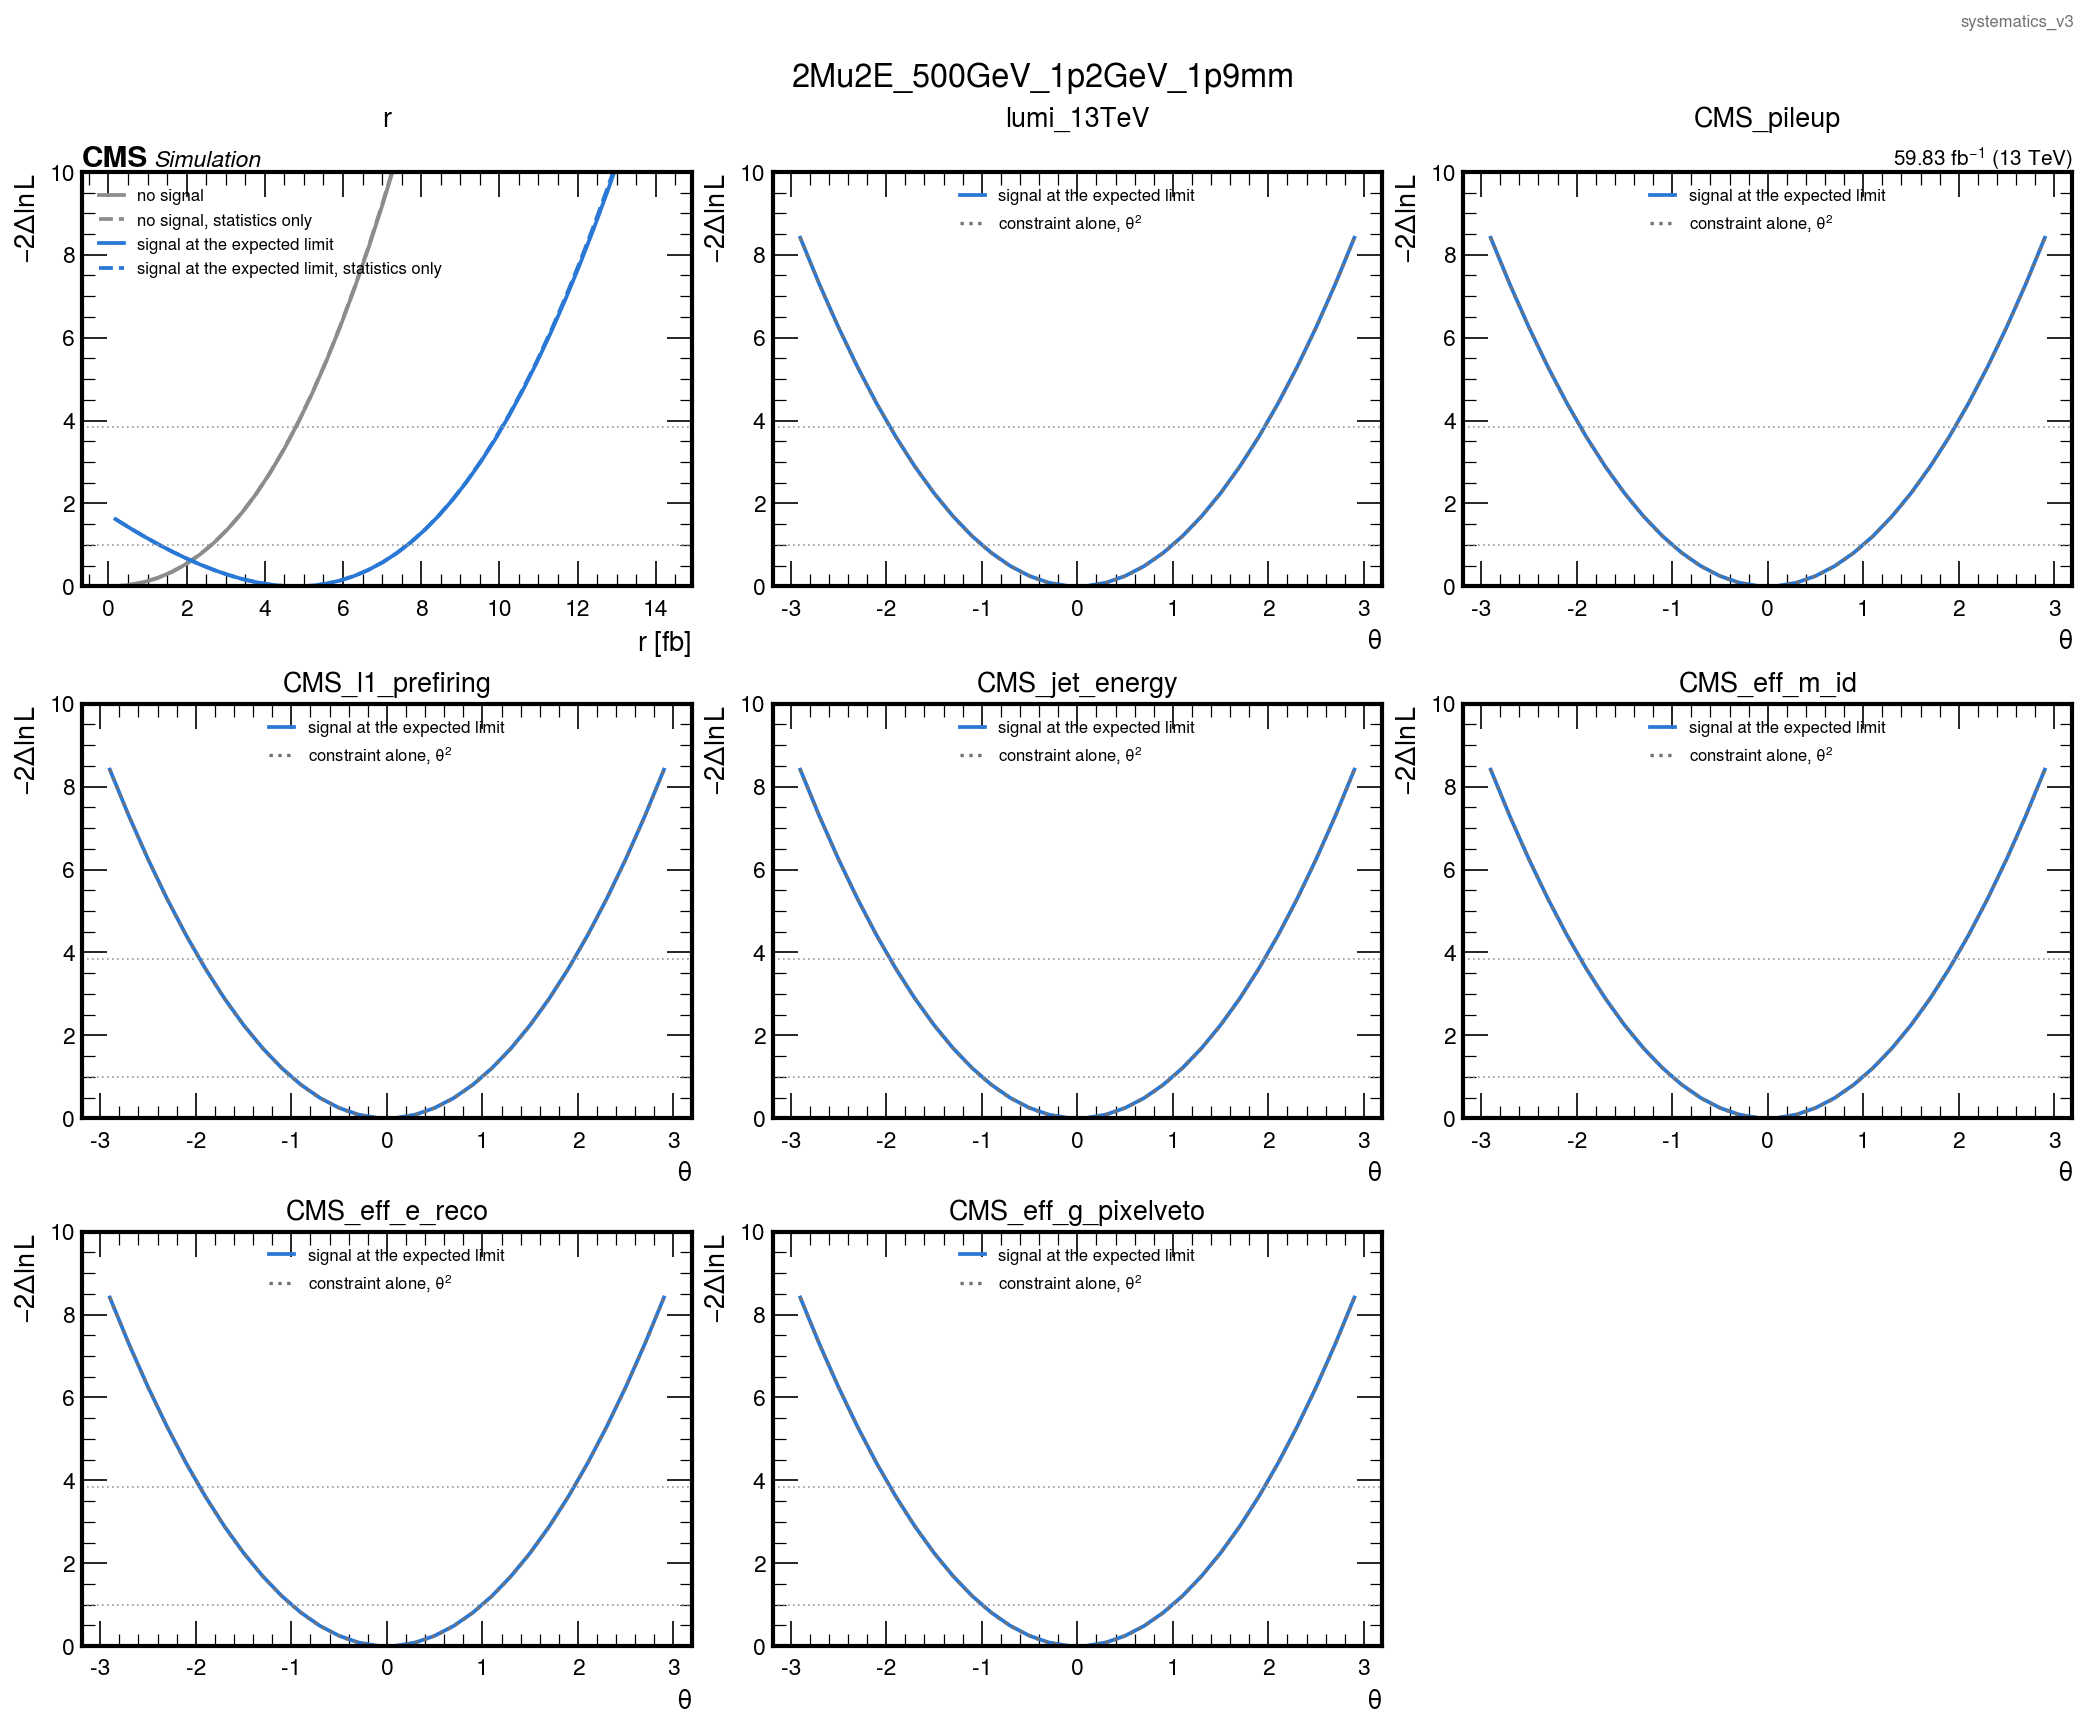

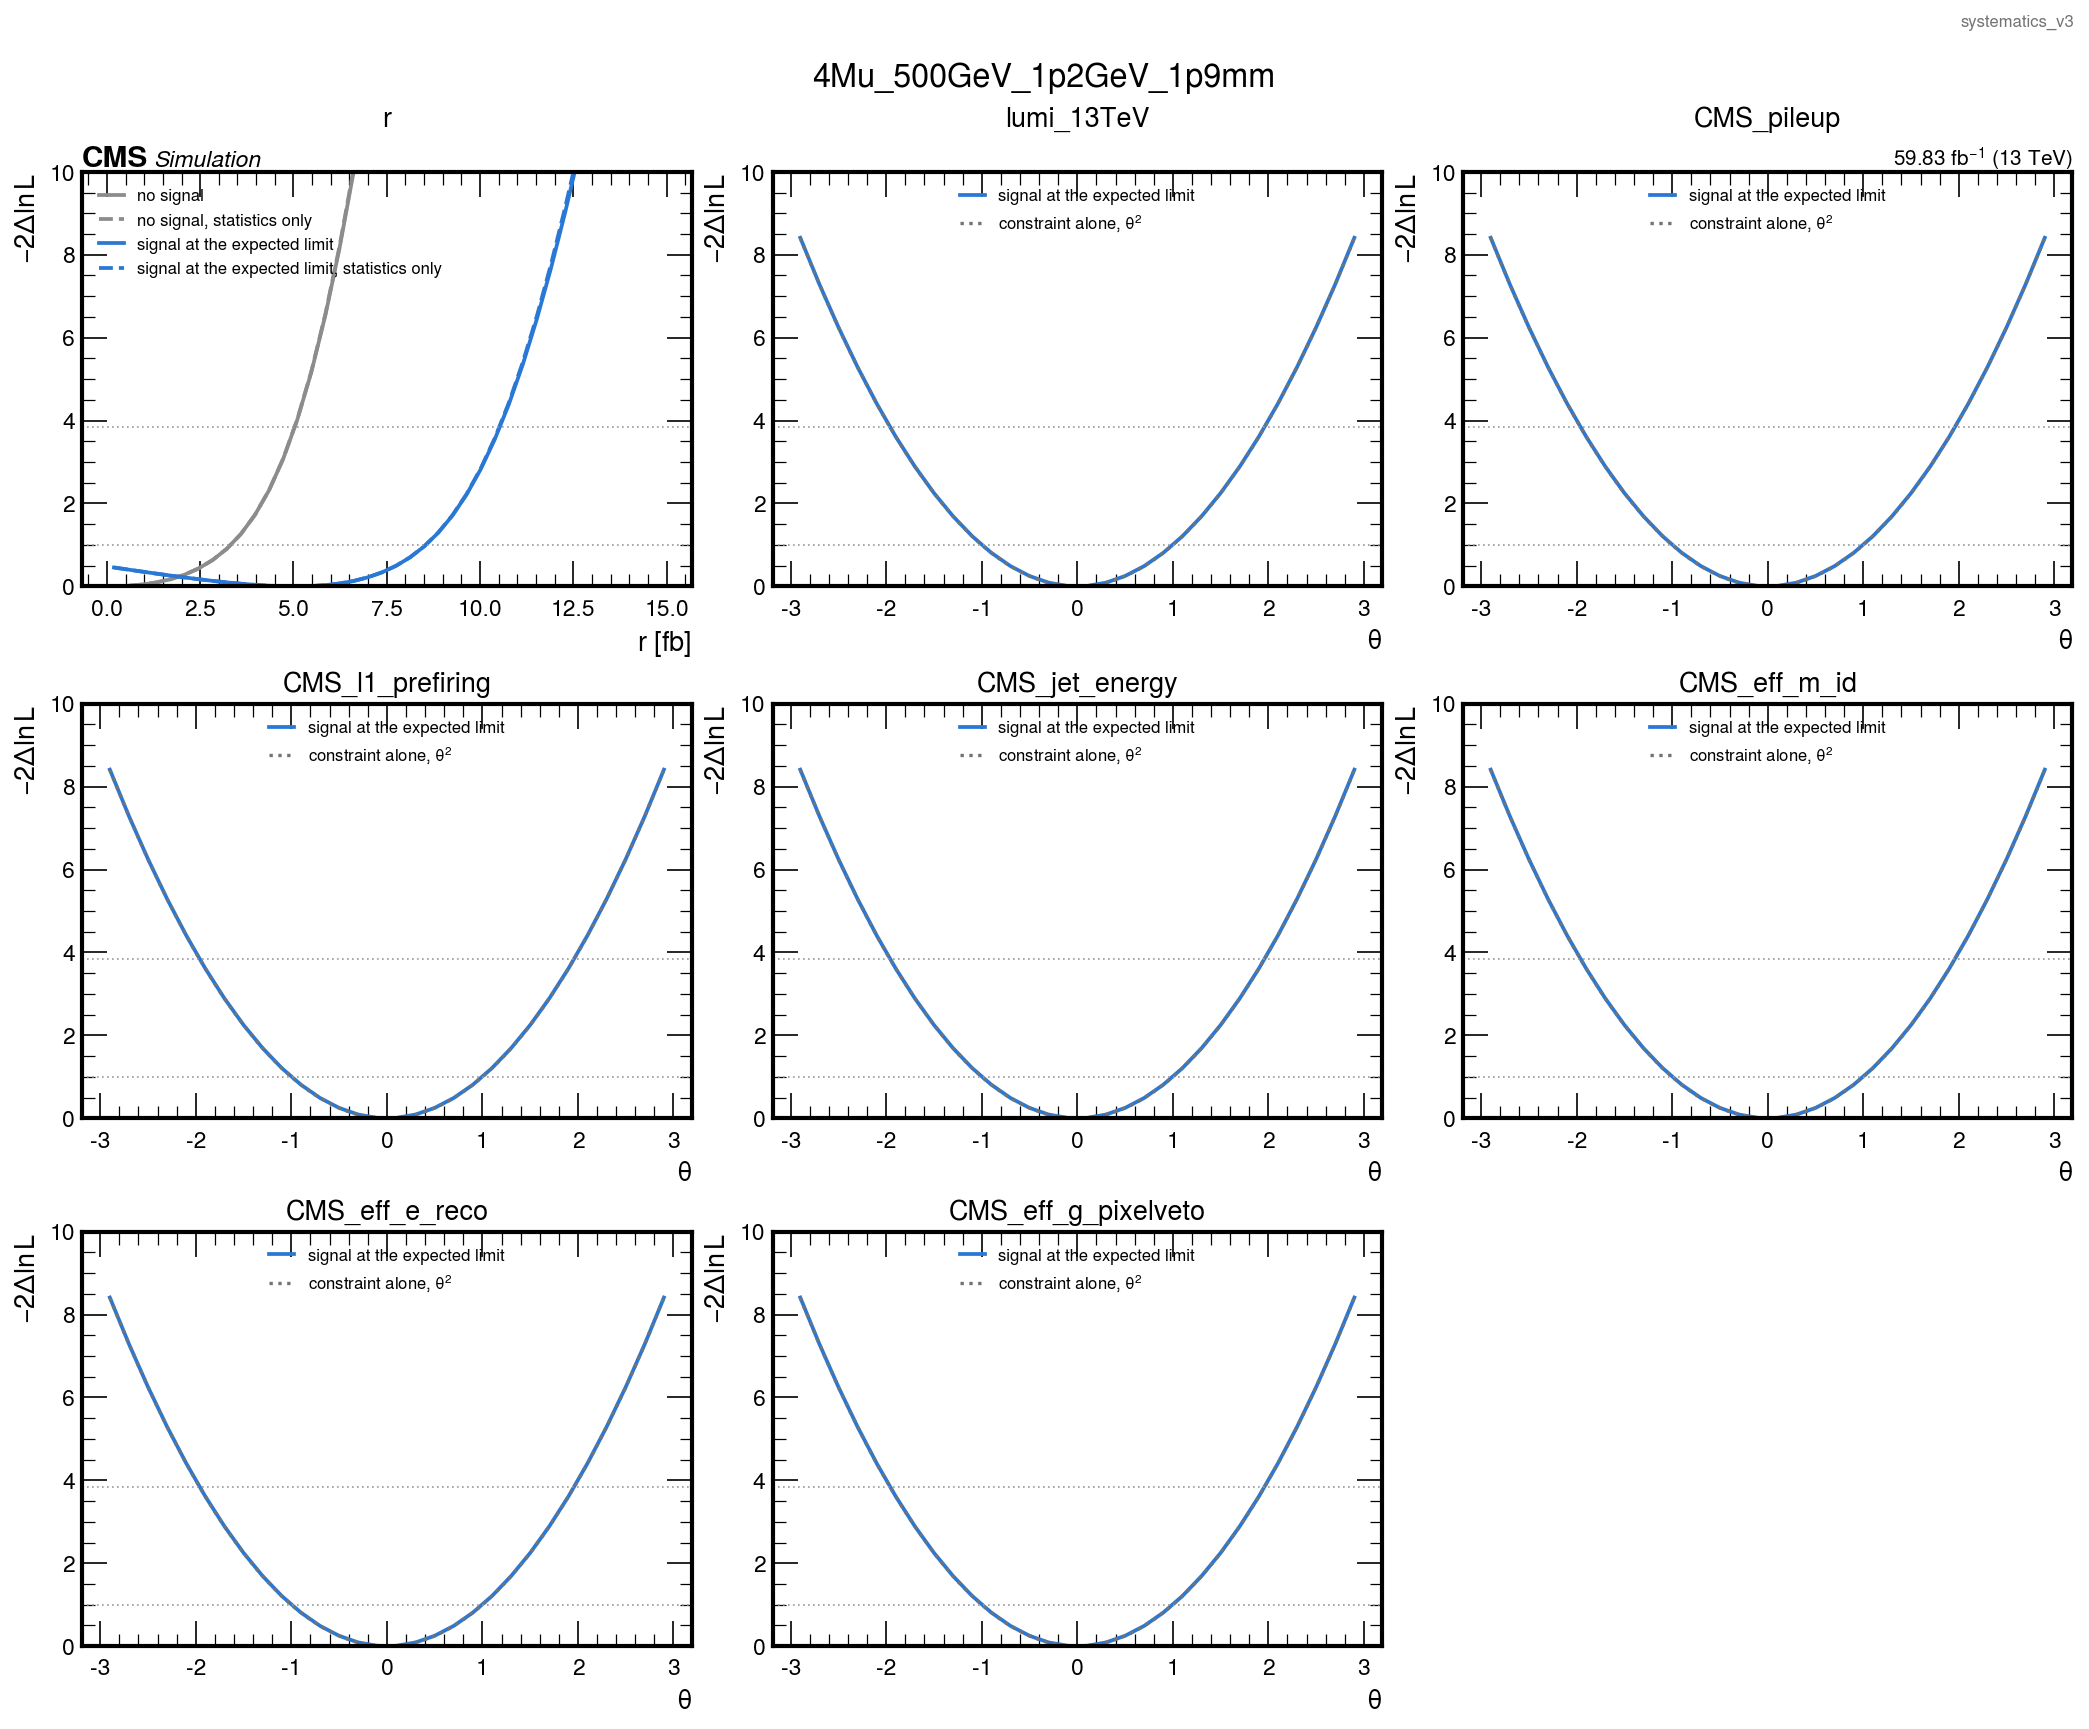

In [3]:
STYLES = {"no signal": dict(color=study.GRAY, ls="-"),
          "no signal, statistics only": dict(color=study.GRAY, ls="--"),
          "signal at the expected limit": dict(color=study.BLUE, ls="-"),
          "signal at the expected limit, statistics only": dict(color=study.BLUE, ls="--")}
for channel, point in POINTS.items():
    card = CARDS / f"datacard_shape_{channel}_{point}.txt"
    outdir = WORK / f"scans_{point}"
    signal = EXPECTED[point]

    def scan(poi, value_range, points, injected, frozen="", name=""):
        """One scan of this point's card, run_combine_scan.py output"""
        name = name or poi
        sysstudy.run_script("run_combine_scan.py", card, "--outdir", outdir, "--poi", poi, f"--range={value_range}",
                            "--points", points, "--expect-signal", f"{injected:.6g}", "--name", name,
                            *(["--freeze", frozen] if frozen else []),
                            combine=COMBINE, log=WORK / f"scan_{point}_{name}.log")
        return json.loads((outdir / f"scan_{name}.json").read_text())

    r_scans = {}
    for label in STYLES:
        r_scans[label] = scan("r", f"0,{3 * signal:.4g}", 40, 0 if label.startswith("no signal") else signal,
                              "allConstrainedNuisances" if label.endswith("statistics only") else "",
                              "r_" + label.replace(",", "").replace(" ", "_"))
    panels = [("r", r_scans, False)]
    panels += [(nuisance, {"signal at the expected limit": scan(nuisance, "-3,3", 30, signal)}, True)
               for nuisance in REGISTRY]
    show(pt.scan_plot(panels, FIGURES, CAMPAIGN, f"scans_{point}", title=point, styles=STYLES))

**Interpretation.** For both points the scans of $r$ with every nuisance and with statistics only
lie on top of each other: the systematics do not widen the likelihood.
* 2Mu2E: with the signal at the expected limit the scan has its minimum at 4.8 fb and is close
  to a parabola, about $-3.5/+2.9$ at $-2\Delta\ln L = 1$, as the impacts of notebook 04 give;
  the background-only scan crosses 3.84 at the expected limit of 4.8 fb.
* 4Mu: the background-only scan is not the straight line of a counting experiment without
  background, since the predicted background is 70 events; it crosses 3.84 at the expected limit
  of 5.0 fb. With the signal injected the scan is flat towards zero: $-2\Delta\ln L$ is 0.5 at
  $r = 0$, so zero lies inside the 68% interval, as the toys near zero of section 5 show.
* The scan of every systematic lies on $\theta^2$: the data add nothing to the constraints, as for
  any nuisance that acts on the signal alone.

**For the analysis:** the likelihoods are smooth, with one minimum, and the systematics leave
them unchanged. A nuisance scan that departs from $\theta^2$ (narrower: constrained by the data;
off-centre: pulled) is what to look for once nuisances on the background are added.

## 7. Correlations

The parameters are ordered as $r$, the systematics, the statistical uncertainties of the
simulated signal (`mcstat`), and the free background parameters of regions B, C and D;
coefficients of at least 0.1 in size are printed. The fit status is printed below each
matrix: anything but 0 means that MINUIT could not determine the uncertainty of every
parameter.

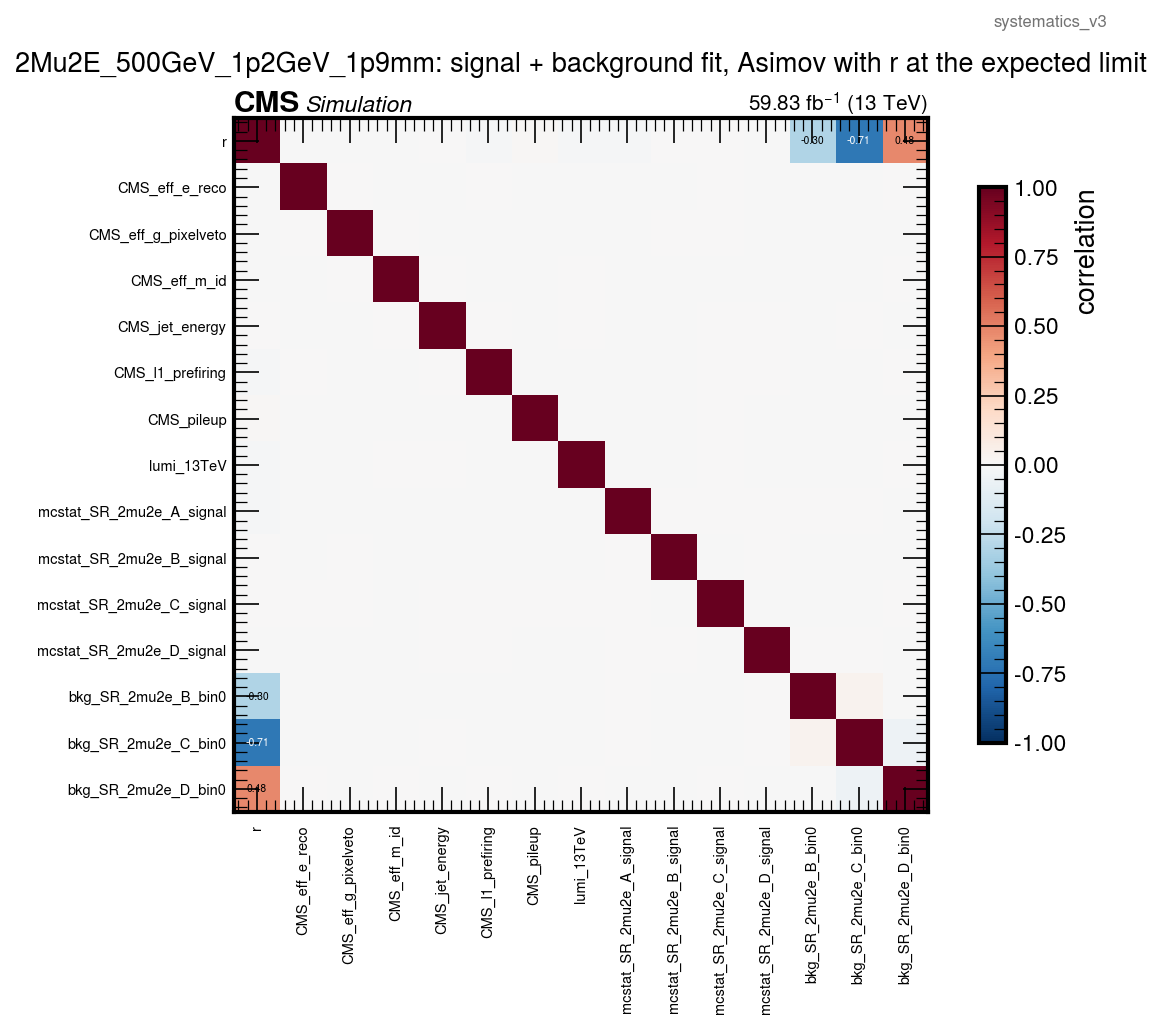

2Mu2E_500GeV_1p2GeV_1p9mm: fit status 0


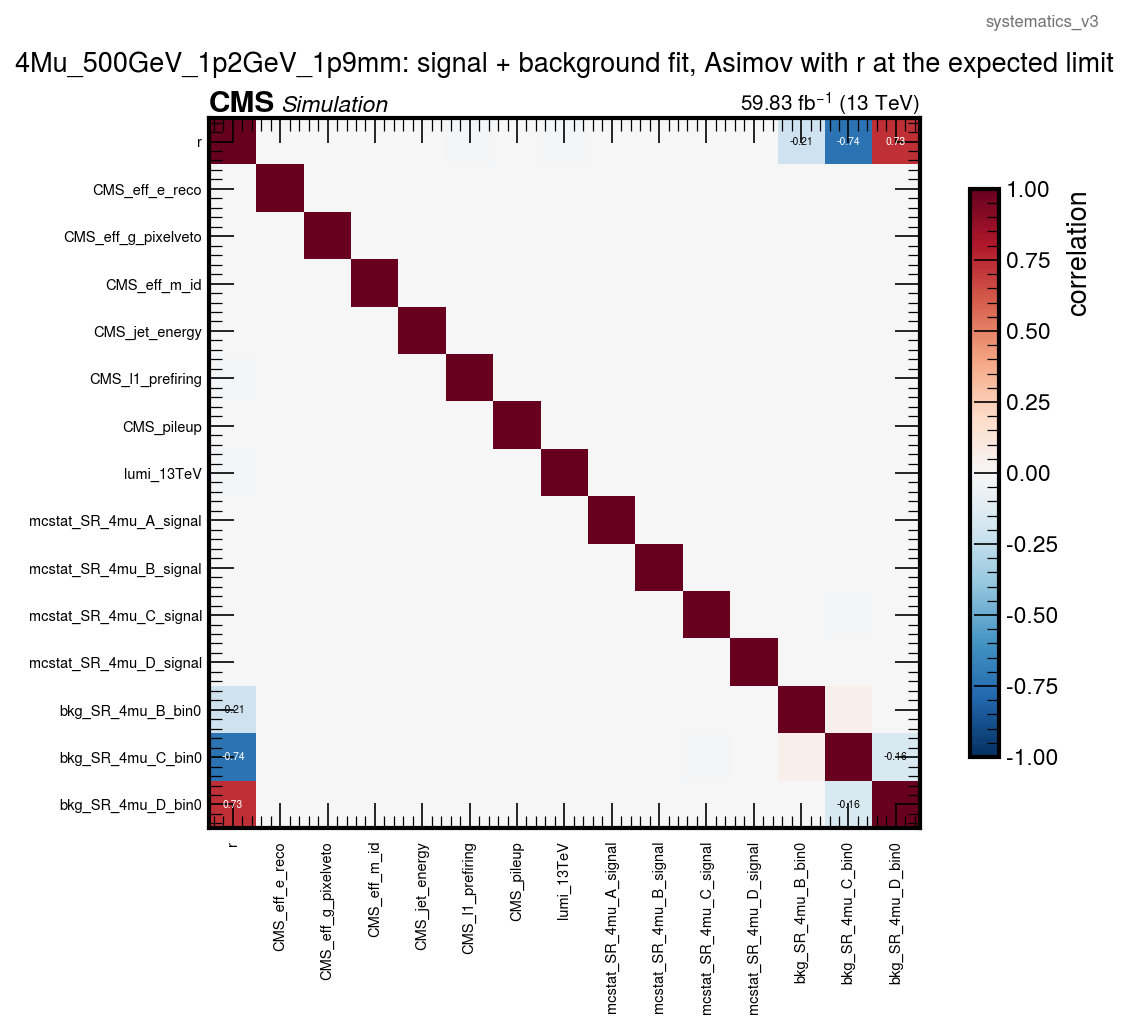

4Mu_500GeV_1p2GeV_1p9mm: fit status 0


In [4]:
def order(name):
    """r first, then the systematics, the signal MC statistics and the background parameters"""
    return (name != "r", name not in REGISTRY, name.startswith("bkg_"), name)


for channel, point in POINTS.items():
    outdir = WORK / f"fit_{point}"
    sysstudy.run_script("run_combine_pulls.py", CARDS / f"datacard_shape_{channel}_{point}.txt",
                        "--outdir", outdir, "--expect-signal", f"{EXPECTED[point]:.6g}",
                        combine=COMBINE, log=WORK / f"fit_{point}.log")
    fit = json.loads((outdir / "pulls.json").read_text())
    correlation = fit["correlation"]["fit_s"]
    index = sorted(range(len(correlation["names"])), key=lambda i: order(correlation["names"][i]))
    show(pt.correlation_plot([correlation["names"][i] for i in index],
                             [[correlation["matrix"][i][j] for j in index] for i in index],
                             FIGURES, CAMPAIGN, f"correlations_{point}",
                             title=f"{point}: signal + background fit, Asimov with r at the expected limit"))
    print(f"{point}: fit status {fit['status'].get('fit_s')}")

**Interpretation.** The systematics are uncorrelated with everything, $r$ included (at most 0.015
in size): on the Asimov dataset they keep their pre-fit values and trade off against no other
parameter. The structure is in $r$ and the three background parameters, as the ABCD estimate
$B\cdot C/D$ makes it: $r$ is anti-correlated with B and C, which raise the predicted background,
and correlated with D, which lowers it.
* 2Mu2E: −0.30 with B, −0.71 with C (17 events) and +0.48 with D (30 events).
* 4Mu: −0.21 with B, −0.74 with C (5 events) and +0.73 with D (3 events).

The smallest control regions weigh most: C in 2mu2e, and C and D about equally in 4mu. Both fits
converge with status 0.

**For the analysis:** the uncertainty of $r$ comes from the statistics of the control regions,
mostly from the smallest of them, not from the systematics.

Everything but the copies of the cards goes to EOS, and the local working directory is removed.

In [5]:
for copies in WORK.glob("cards*"):
    shutil.rmtree(copies)
sysstudy.upload(WORK, OUTPUT_DIR)
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v3_limits_data/fit_checks
